# Lesson 3 — Loss: measuring wrongness so a machine can fix it

Lesson 3 — Loss: measuring wrongness so a machine can fix it
============================================================

GURU NOTE
---------
In Lesson 2 we GUESSED the weights. To let a machine find good weights, it needs a
single number telling it how wrong it currently is — the "loss". Then training
(Lesson 4) is just: change the weights to make that number smaller.

You might think "just use accuracy — % correct". Here is the deep reason that
fails, and why every classifier including yours uses LOG-LOSS instead:

  * Accuracy only cares whether p is above or below 0.5. Predicting 0.51 vs 0.99
    for a true attack counts the same. So accuracy is FLAT — nudging a weight
    usually doesn't change it at all, and when it does it JUMPS. You can't walk
    downhill on a staircase.
  * Log-loss cares HOW confident you were. It rewards confident-and-right and
    savagely punishes confident-and-wrong, smoothly. Smooth = you can always tell
    which way is downhill. That's what makes learning possible.

This is the objective `fit_logistic` minimizes in your repo.

Run me:  python lessons/lesson_03_loss.py

## Setup

These notebooks *import* the real code from `lessons/*.py` — one source of truth, no forked copies. This cell finds that folder.

In [1]:
import sys, pathlib
for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (base / 'lessons' / '_util.py').exists():
        sys.path.insert(0, str(base / 'lessons'))
        print('lessons on path:', base / 'lessons'); break
else:
    raise RuntimeError('Open this notebook inside the xorguard-ml-course folder.')

lessons on path: /Users/anil/Documents/developer/vscodeworkspaces/xordev/xorguard-ml-course/lessons


## The key code (shown live from the source file)

Read it, then copy any function into a new cell and tweak it — the originals live in `lessons/lesson_03_loss.py`.

In [2]:
import inspect
from lesson_03_loss import log_loss
for fn in (log_loss,):
    print(inspect.getsource(fn)); print('-' * 72)

def log_loss(y, p, eps: float = 1e-12):
    """Binary cross-entropy: the average 'surprise' of the true labels.

    For each example:
        if the truth is 1 (attack):  cost = -log(p)      -> 0 if p=1, huge if p=0
        if the truth is 0 (benign):  cost = -log(1 - p)  -> 0 if p=0, huge if p=1

    We clip p away from exactly 0/1 so log() never blows up to infinity.
    Lower loss = better. Perfect confident predictions -> loss 0.
    """
    p = np.clip(p, eps, 1 - eps)
    return float(np.mean(-(y * np.log(p) + (1 - y) * np.log(1 - p))))

------------------------------------------------------------------------


## A picture

A real plot (matplotlib) in place of the terminal's ASCII. Re-run after changing inputs to build intuition.

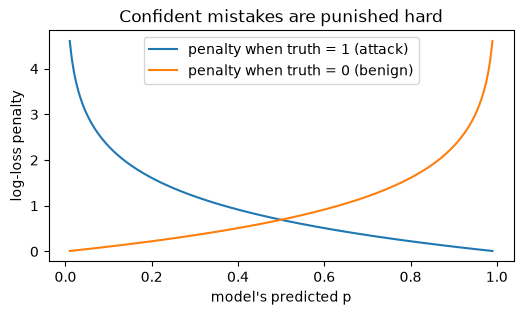

In [3]:
import numpy as np, matplotlib.pyplot as plt
p = np.linspace(0.01, 0.99, 200)
plt.figure(figsize=(6, 3))
plt.plot(p, -np.log(p), label='penalty when truth = 1 (attack)')
plt.plot(p, -np.log(1 - p), label='penalty when truth = 0 (benign)')
plt.xlabel("model's predicted p"); plt.ylabel('log-loss penalty')
plt.title('Confident mistakes are punished hard'); plt.legend()
plt.show()

## Run the full narrated lesson

This executes the same walkthrough as `python lessons/lesson_03_loss.py`, printing each step with its result.

In [4]:
from lesson_03_loss import main
main()


════════════════════════════════════
Lesson 3 — Loss: measuring wrongness
════════════════════════════════════

▸ The shape of the penalty. Suppose the TRUTH is 1 (a real attack).
    Cost = -log(p). Watch how the penalty explodes as p -> 0
    (i.e. as the model confidently says 'benign' about a real attack):

  cost when truth=1:  x-axis = model's p,  y-axis = penalty
   •                                                       
                                                           
    •                                                      
     •                                                     
      •                                                    
       •••                                                 
          •••                                              
             ••••••                                        
                   ••••••••                                
                           •••••••••••••                   
                          

## Exercises

Try these in new cells below. Worked answers are in `solutions/lesson_03_solution.py`.

```
1. What is the log-loss of a model that predicts EXACTLY p=0.5 for every
   example? Derive it by hand (hint: -log(0.5)) and confirm with w_zero above.

2. Construct weights whose ACCURACY is high (say 90%) but whose LOSS is worse
   than the hand-tuned model. (Hint: be correct but barely — predictions near
   0.5 — versus correct AND confident.) This shows why the two disagree.

3. Add a single catastrophic example: a real attack (label 1) that the
   hand-tuned model scores p=0.001. Append it and recompute the loss. Watch one
   confident mistake dominate the average. This is why outliers matter.
```

In [5]:
# your work here
